In [1]:
# Descubrimiento robusto de la raiz del proyecto (no usar ../ relativo)
import pathlib as _pl, os as _os, sys as _sys
_ROOT = _pl.Path().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
_os.chdir(_ROOT)
if str(_ROOT) not in _sys.path:
    _sys.path.insert(0, str(_ROOT))
if str(_ROOT / "src") not in _sys.path:
    _sys.path.insert(0, str(_ROOT / "src"))

# Entorno de ejecucion reproducible: TF en 1 hilo (antes de importar Keras/TF;
# `ejecutar_shap_c` carga el bundle con lazy-load dentro de la funcion).
_os.environ["TF_NUM_INTEROP_THREADS"] = "1"
_os.environ["TF_NUM_INTRAOP_THREADS"] = "1"
_os.environ["OMP_NUM_THREADS"] = "1"
_os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import shap as _shap
print("cwd:      ", _os.getcwd())
print("python:   ", _sys.version.split()[0])
print("shap:     ", _shap.__version__)

# --- MLflow live (mlflow-live-notebooks): env BEFORE any TF/Keras import ---
_os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")
_os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
_os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
_os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")
_os.environ.setdefault("OMP_NUM_THREADS", "1")
from ds02_rul.mlflow_live import log_live_run, persist_timings, setup_mlflow
setup_mlflow()
print("mlflow live: store=mlruns experiment=ds02-clase (fuente=live_notebook)")


cwd:       C:\Users\mikel\Desktop\Pruebas\nasa
python:    3.12.10
shap:      0.54.1
mlflow live: store=mlruns experiment=ds02-clase (fuente=live_notebook)


## Trazabilidad NB07 — SHAP bundle C (Grupo SEGURO, solo Markdown)

1. **Bootstrap:** celda 0 no es lógica del modelo: fija `_ROOT`, `cwd` y `sys.path` + entorno reproducible (TF a 1 hilo *antes* de importar Keras/TF). Sin ese orden, el SHAP carga con otro paralelismo.
2. **Imports (doble grafía):** solo `from src.ds02_rul.shap_c import ejecutar_shap_c` (celda 2, con prefijo `src`) + `shap`/`time`. No usa la ruta corta `ds02_rul.*` en este notebook; la doble grafía le afectaría solo si se añaden imports del paquete.
3. **Alias:** ninguno de los 7 alias del grupo: sin `evaluar_clase`, `make_pipeline`, `FEATURE_COLS`, `evaluate_predictions`, `HybridStackingEnsemble`. Su única función es `ejecutar_shap_c` (`src/ds02_rul/shap_c.py`).
4. **Artefactos que ESCRIBE:** `resultados/shap_bundle_C/` al ejecutar la celda 2 (vía `ejecutar_shap_c`): 3 CSV (`shap_bilstm`, `shap_lgbm`, `shap_meta`), 3 PNG de barras (`bar_*.png`) y `metadata.json`. Son salidas de explicación, no de modelo.
5. **Artefactos que solo LEE:** bundle C congelado `models/ensemble.joblib` (seed 42, `load_ensemble` dentro de `ejecutar_shap_c`) + datos de fondo fold-0. No escribe `models/` ni toca NB01-06.
6. **Escritor .py:** bundle C ← `src/ds02_rul/bundle_c.py:entrenar`; SHAP ← `src/ds02_rul/shap_c.py:ejecutar_shap_c`. **NB07 NO lo invoca:** no entrena el bundle ni re-escribe `models/`; solo lo carga en lectura y vuelca la explicación. El notebook se puede reconstruir sin ejecutarlo con `python scripts/build_07_shap_c_notebook.py`.
7. **Celdas display sin lógica (solo presentación):** 4 — muestra las 3 barras `bar_*.png` ya calculadas por la celda 2; no calcula importancias ni toca artefactos.

> **Procedencia:** bundle C ← `src/ds02_rul/bundle_c.py:entrenar` (seed 42) → `models/ensemble.joblib` + `bilstm_ds02.keras` + `models/ds02_manifest.json` vía `src/ds02_rul/persistence.py:202` (`save_ensemble`). NB07 solo lo lee (SHA verificado) y describe el modelo, no el motor: asociaciones no causales, EMA fuera de atribución.


# 07 — SHAP por ramas sobre el bundle C

Cuaderno fino: no entrena nada. Llama a `ejecutar_shap_c`
(`src/ds02_rul/shap_c.py`) sobre el bundle C ya congelado
(`models/ensemble.joblib`, seed 42) en **solo lectura** y muestra lo que deja
en `resultados/shap_bundle_C/`: tres CSV de importancia, tres graficos de
barras y `metadata.json`.

- **BiLSTM**: Permutation agrupado por canal (19 canales de la ventana
  `(50,19)`; `DeepExplainer` no aplica en este entorno — ver nota en el
  modulo).
- **LGBM**: `TreeExplainer` interventional sobre las 93 features tabulares.
- **Meta**: `PermutationExplainer` sobre el ancho real del meta-aprendiz
  (2 = `[p_lstm, p_lgb]`).

Fondo: solo train del fold-0 del GroupKFold(3) por motor (sin test 11/14/15),
seed 42. EMA fuera: no se atribuye.

> SHAP describe el modelo, no el motor: asociaciones no causales.


In [2]:
import time

from ds02_rul.shap_c import ejecutar_shap_c

# Parametros documentados: tamano completo (mismo que N_FILAS/N_FONDO del modulo).
N_FILAS = 200
N_FONDO = 200
SEED = 42

t0 = time.time()
res = ejecutar_shap_c(n_filas=N_FILAS, n_fondo=N_FONDO, seed=SEED, verbose=True)
print(f"ejecutado en {time.time() - t0:.1f} s")
print("[NB07 OK]")
res


Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.
Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


aditividad: bilstm 9.54e-07 | lgbm 3.85e-07 | meta 1.42e-13
guardado: resultados/shap_bundle_C/
ejecutado en 8.2 s
[NB07 OK]


{'bilstm': {'shap_shape': [200, 50, 19],
  'aditividad_max_error': 9.536743306171047e-07,
  'base_value': 14.271074295043945},
 'lgbm': {'shap_shape': [200, 93],
  'aditividad_max_error': 3.852614014476785e-07},
 'meta': {'shap_shape': [200, 2],
  'aditividad_max_error': 1.4210854715202004e-13,
  'n_features_meta': 2},
 'background_units': [2.0, 10.0, 18.0, 20.0],
 'explicadas_units': [5.0],
 'n_background': 200,
 'n_explicadas': 200,
 'out_dir': 'resultados/shap_bundle_C'}

In [3]:
import json

import pandas as pd

OUT = "resultados/shap_bundle_C"

for nombre in ("shap_bilstm", "shap_lgbm", "shap_meta"):
    df = pd.read_csv(f"{OUT}/{nombre}.csv")
    print(f"== {nombre}.csv: {len(df)} filas x {len(df.columns)} columnas ==")
    print(df.head(5).to_string(index=False))
    print()

meta = json.load(open(f"{OUT}/metadata.json", encoding="utf-8"))
print(json.dumps({
    "shap_shapes": meta["shap_shapes"],
    "aditividad_max_error": meta["aditividad_max_error"],
    "n_background": meta["n_background"],
    "n_explicadas": meta["n_explicadas"],
    "nasa_sin_clamp": meta["nasa_sin_clamp"],
    "nota": meta["nota"],
}, indent=2, ensure_ascii=False))


== shap_bilstm.csv: 19 filas x 4 columnas ==
 feature  mean_abs_shap  mean_shap  std_shap
cyc_norm      24.063986  24.063986  4.163579
     T50      16.600309  10.688215 17.341518
      P2       3.676942   2.586649  3.753463
     TRA       3.308217   1.418044  3.706669
      Nc       2.628257   1.661995  2.973637

== shap_lgbm.csv: 93 filas x 4 columnas ==
       feature  mean_abs_shap  mean_shap  std_shap
      cyc_norm      12.908727  12.908727  2.733106
      T50_mean       9.135080   9.135080  0.799317
      T48_mean       5.613403   5.613403  0.113817
T50_last10mean       1.294917   1.294917  0.044378
       Wf_mean       0.765718   0.765718  0.005605

== shap_meta.csv: 2 filas x 4 columnas ==
feature  mean_abs_shap  mean_shap  std_shap
  p_lgb      20.151415  20.151415  2.126147
 p_lstm       8.088357   8.088357  0.579126

{
  "shap_shapes": {
    "bilstm": [
      200,
      50,
      19
    ],
    "lgbm": [
      200,
      93
    ],
    "meta": [
      200,
      2
    ]
  },


== bar_bilstm.png ==


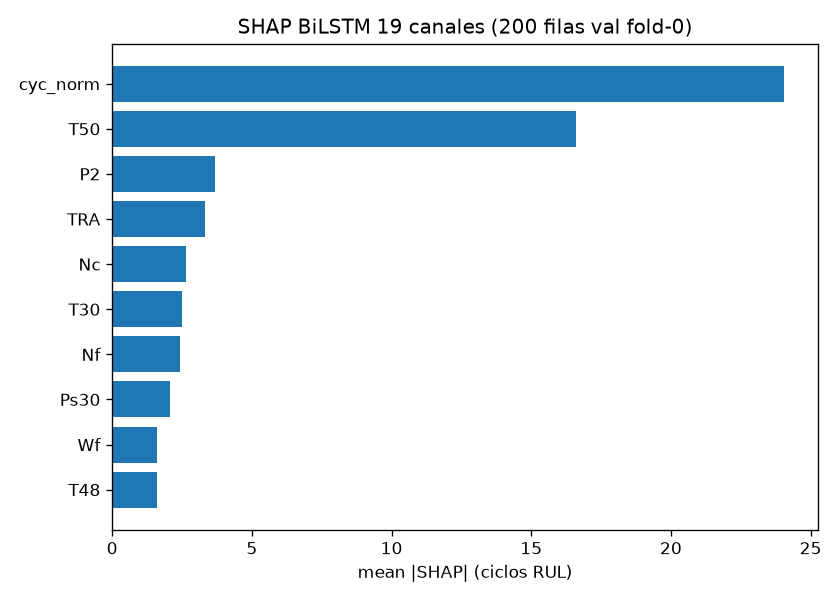

== bar_lgbm.png ==


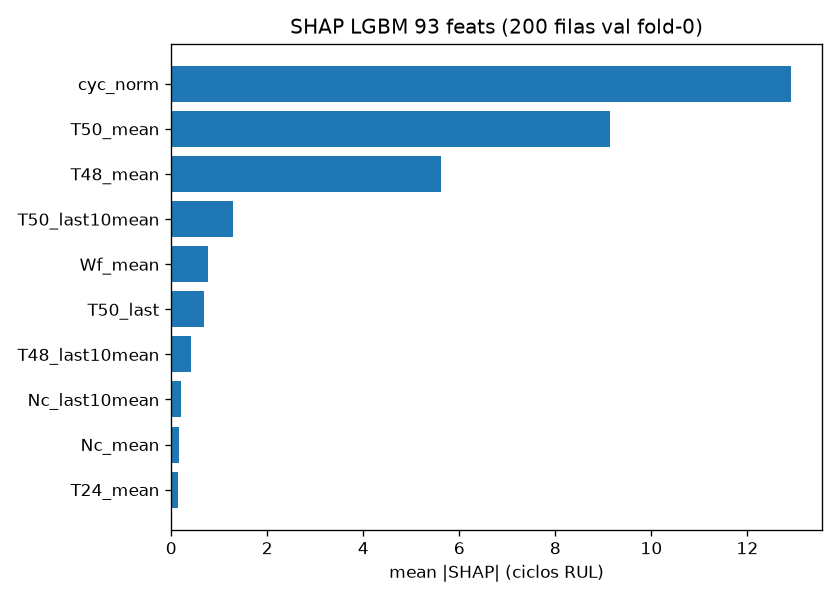

== bar_meta.png ==


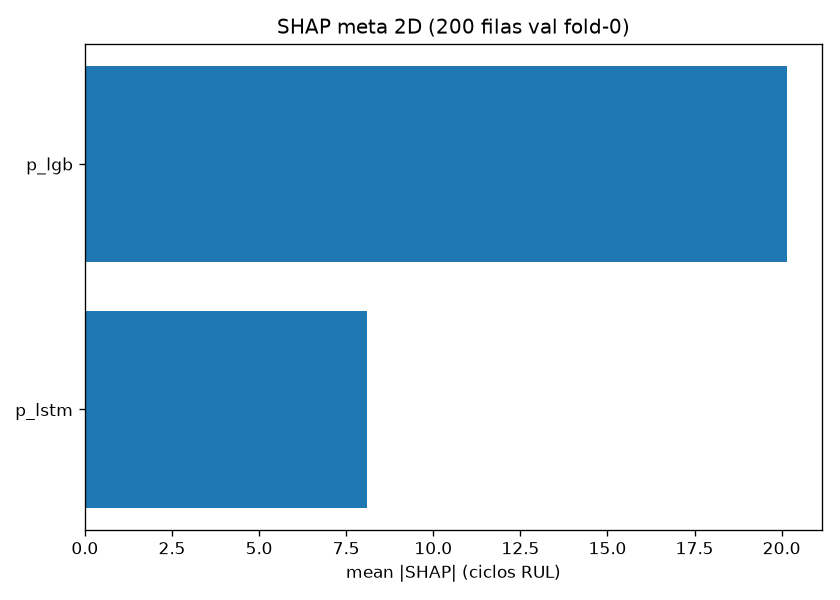

In [4]:
from IPython.display import Image, display

for rama in ("bilstm", "lgbm", "meta"):
    print(f"== bar_{rama}.png ==")
    display(Image(f"resultados/shap_bundle_C/bar_{rama}.png"))


## Lectura y limites

- Los valores son importancias del modelo sobre la validacion fold-0:
  describen como el modelo reparte su salida, no el comportamiento del motor.
- La rama BiLSTM agrega por canal: se pierde el detalle dentro de la ventana
  de 50 pasos (limitacion declarada en `src/ds02_rul/shap_c.py`).
- La EMA de produccion queda fuera de la atribucion y no aparece en estos CSV.
- `resultados/shap_bundle_C/` se regenera al ejecutar la celda de SHAP;
  `models/` y NB01-06 no se tocan. Para reconstruir este cuaderno sin
  ejecutarlo: `python scripts/build_07_shap_c_notebook.py` (con el
  interprete del `.venv`).

> SHAP describe el modelo, no el motor: asociaciones no causales.


## Defensa — dónde vive el train oficial (solo Markdown)

> **Esta celda es texto Markdown añadido para la defensa; no se ha ejecutado nada y no cambia código, outputs ni `execution_count`.**

- **Entreno oficial del bundle C:** `src/ds02_rul/bundle_c.py:entrenar` `entrenar()` vía `src/ds02_rul/persistence.py:202` `save_ensemble()` — **NB07 NO lo invoca**: solo lo carga en lectura.
- **SHAP oficial:** `src/ds02_rul/shap_c.py` `ejecutar_shap_c`, llamado en la celda 3 (única llamada, bien delegada). NB07 **no entrena nada**; escribe solo `resultados/shap_bundle_C/` (explicación, no modelo).
- Aviso de 20 s: «No entrena nada: llama a `ejecutar_shap_c` sobre el bundle congelado en solo lectura y vuelca la explicación.»


In [5]:
# --- MLflow live: SHAP (params-only run; explanation, not training) ---
from ds02_rul.mlflow_live import log_live_run, persist_timings
_res = globals().get("res")
_metrics = {}
if isinstance(_res, dict):
    for _k in ("aditividad_max_error", "n_background", "n_explicadas"):
        if _k in _res:
            _metrics[_k] = float(_res[_k])
log_live_run("live__nb07_shap_c",
             params={"notebook": "07_shap_c_bundle_c", "seed": 42,
                     "n_filas": globals().get("N_FILAS", 200),
                     "n_fondo": globals().get("N_FONDO", 200)},
             metrics=_metrics, notebook="07")
print("[NB07 MLflow live OK]")


[NB07 MLflow live OK]
